In [ ]:
#Mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import tensorflow as tf
import numpy as np
from PIL import Image
import glob

def load_tif_dataset(directory, label_map, image_size=(224, 224)):
    images, labels = [], []

    for class_name, label in label_map.items():
        class_dir = os.path.join(directory, class_name)
        tif_files = glob.glob(os.path.join(class_dir, "*.tif"))

        for file_path in tif_files:
            img = Image.open(file_path).convert("RGB")
            img = img.resize(image_size)
            img_array = np.array(img) / 255.0
            images.append(img_array)
            labels.append(label)

    images = np.array(images, dtype=np.float32)
    labels = np.array(labels, dtype=np.float32)

    return tf.data.Dataset.from_tensor_slices((images, labels))


label_map = {'iceberg': 0, 'non_iceberg': 1}


train_ds = load_tif_dataset("/content/drive/My Drive/Iceberg_classification/data/train", label_map)
val_ds   = load_tif_dataset("/content/drive/My Drive/Iceberg_classification/data/val", label_map)
test_ds  = load_tif_dataset("/content/drive/My Drive/Iceberg_classification/data/test", label_map)


BATCH_SIZE = 16
train_ds = train_ds.shuffle(100).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds  = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing import image_dataset_from_directory


#augment data
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

#load resnet50 with base layers
base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  #freeze base layer weights

#build model
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


model.summary()


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)


test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc:.4f}")


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1             │ (None, 224, 224, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ sequential (Sequential)   │ (None, 224, 224, 3)    │              0 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ get_item (GetItem)        │ (None, 224, 224)       │              0 │ sequential[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ get_item_1 (GetItem)      │ (None, 224, 224)       │              0 │ sequential[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ get_item_2 (GetItem)      │ (None, 224, 224)       │              0 │ sequential[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stack (Stack)             │ (None, 224, 224, 3)    │              0 │ get_item[0][0],        │
│                           │                        │                │ get_item_1[0][0],      │
│                           │                        │                │ get_item_2[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add (Add)                 │ (None, 224, 224, 3)    │              0 │ stack[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ resnet50 (Functional)     │ (None, 7, 7, 2048)     │     23,587,712 │ add[0][0]              │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ global_average_pooling2d  │ (None, 2048)           │              0 │ resnet50[0][0]         │
│ (GlobalAveragePooling2D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)         │ (None, 2048)           │              0 │ global_average_poolin… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 128)            │        262,272 │ dropout[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 128)            │              0 │ dense[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_1 (Dense)           │ (None, 1)              │            129 │ dropout_1[0][0]        │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 43s 4s/step - accuracy: 0.4886 - loss: 0.8084 - val_accuracy: 0.4545 - val_loss: 0.6963
Epoch 2/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.5743 - loss: 0.7155 - val_accuracy: 0.4545 - val_loss: 0.7231
Epoch 3/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 4s/step - accuracy: 0.5516 - loss: 0.6764 - val_accuracy: 0.4545 - val_loss: 0.7367
Epoch 4/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.5847 - loss: 0.7119 - val_accuracy: 0.4545 - val_loss: 0.7292
Epoch 5/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.5622 - loss: 0.7100 - val_accuracy: 0.4545 - val_loss: 0.7180
Epoch 6/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.4931 - loss: 0.7284 - val_accuracy: 0.4545 - val_loss: 0.7143
Epoch 7/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.5095 - loss: 0.6971 - val_accuracy: 0.4545 - val_loss: 0.7053
Epoch 8/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.5408 - loss: 0.7214 - val_accuracy: 0.4545 - val_loss: 0.7026
Epoch 9/

In [ ]:
base_model.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="binary_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 182s 15s/step - accuracy: 0.6347 - loss: 0.8082 - val_accuracy: 0.8182 - val_loss: 0.6399
Epoch 2/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 113s 12s/step - accuracy: 0.7545 - loss: 0.4169 - val_accuracy: 0.5909 - val_loss: 0.6682
Epoch 3/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 116s 13s/step - accuracy: 0.9445 - loss: 0.2345 - val_accuracy: 0.5455 - val_loss: 0.6698
Epoch 4/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 136s 12s/step - accuracy: 0.9843 - loss: 0.1259 - val_accuracy: 0.6818 - val_loss: 0.6675
Epoch 5/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 112s 12s/step - accuracy: 0.9451 - loss: 0.1554 - val_accuracy: 0.4545 - val_loss: 0.6874


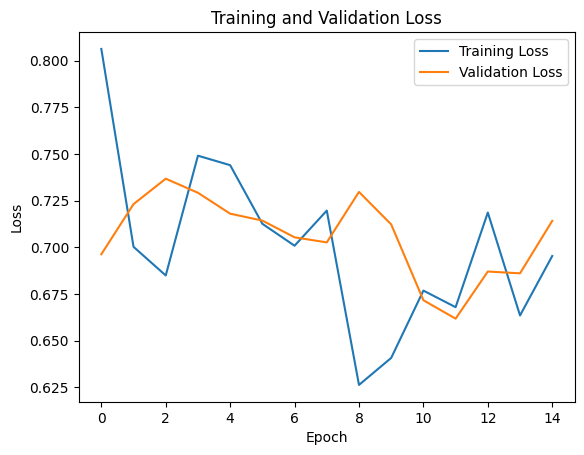

In [ ]:
import matplotlib.pyplot as plt

#plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 179ms/step - accuracy: 0.4804 - loss: 0.6816
Test Accuracy: 0.4706


In [ ]:
model.save('/content/drive/My Drive/Colab Notebooks/models/ResNet50_iceberg.keras')

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


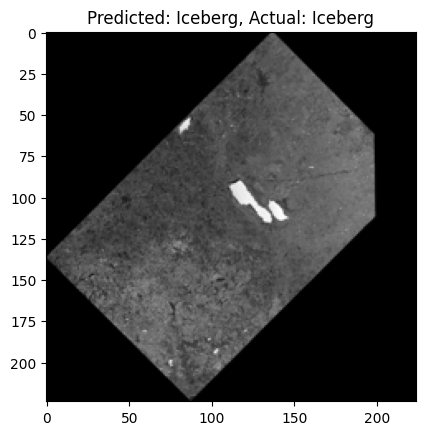

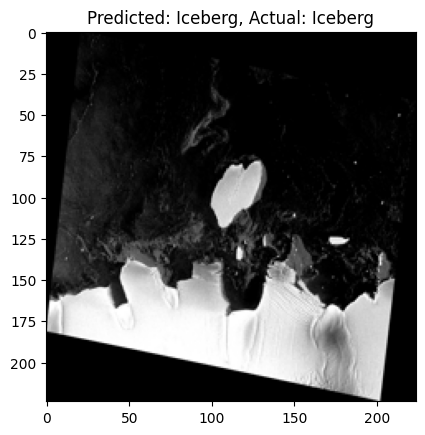

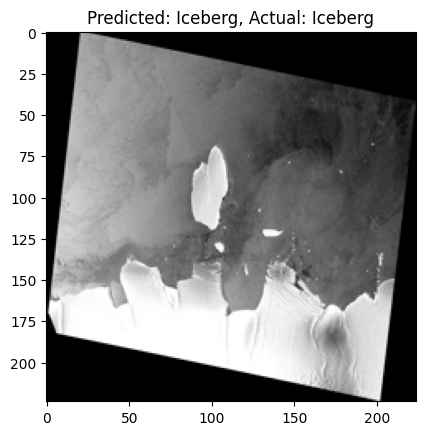

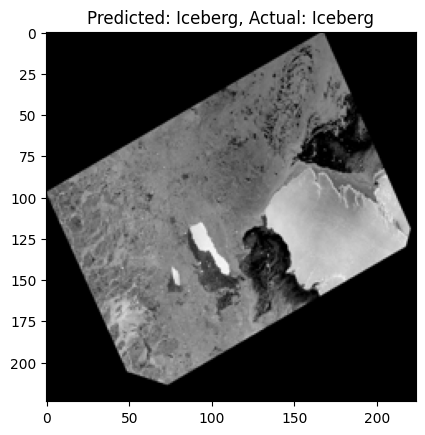

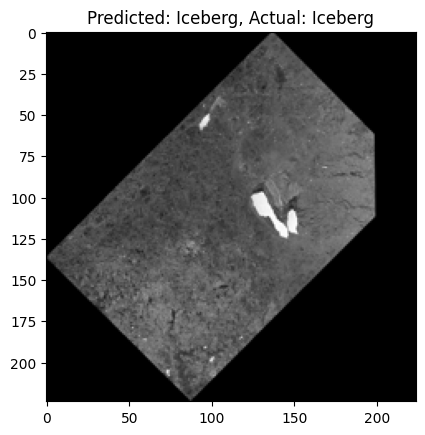

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#test images and labels
image_batch, label_batch = next(iter(test_ds))

#predictions on test set
predictions = model.predict(image_batch)

#display
num_images_to_display = 5
for i in range(num_images_to_display):
  plt.figure()
  plt.imshow(image_batch[i])
  predicted_label = "Iceberg" if predictions[i][0] < 0.5 else "Non-Iceberg"  #0.5 threshold
  actual_label = "Iceberg" if label_batch[i] == 0 else "Non-Iceberg"
  plt.title(f"Predicted: {predicted_label}, Actual: {actual_label}")
  plt.show()

Evaluation Scoring

In [ ]:
#precision

from sklearn.metrics import precision_score


y_true = []
y_pred = []
for images, labels in test_ds:
    y_true.extend(labels.numpy())
    y_pred.extend(model.predict(images).flatten())


y_pred_binary = (np.array(y_pred) > 0.3).astype(int) #0.3 threshold

precision = precision_score(y_true, y_pred_binary, zero_division=1)
print(f"Precision: {precision:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
Precision: 0.4706


In [ ]:
#recall

from sklearn.metrics import recall_score

recall = recall_score(y_true, y_pred_binary)
print(f"Recall: {recall:.4f}")

Recall: 1.0000


In [ ]:
#f1 score

from sklearn.metrics import f1_score

f1 = f1_score(y_true, y_pred_binary)
print(f"F1-Score: {f1:.4f}")

F1-Score: 0.6400


In [ ]:
#auc(area under the ROC Curve)

from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_true, y_pred)
print(f"AUC: {auc:.4f}")

AUC: 1.0000


Inference

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model('/content/drive/My Drive/Colab Notebooks/models/ResNet50_iceberg.keras')

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def preprocess_image(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array

new_image_path = '/content/drive/My Drive/Colab Notebooks/Data/iceberg_unseen.tiff'
preprocessed_image = preprocess_image(new_image_path)

In [ ]:
prediction = model.predict(preprocessed_image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step


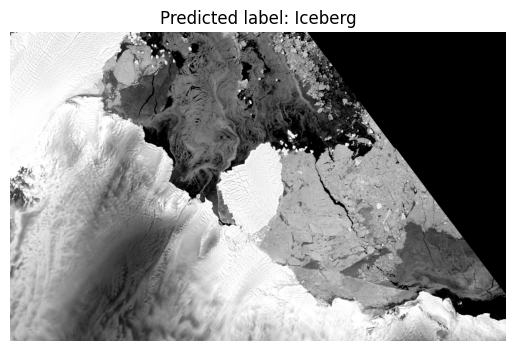

In [ ]:
threshold = 0.3

if prediction[0][0] > threshold:
    predicted_label = "Non-Iceberg"
else:
    predicted_label = "Iceberg"

#display image
img = Image.open(new_image_path)
plt.imshow(img)
plt.title(f"Predicted label: {predicted_label}")
plt.axis('off')
plt.show()